# Volatility Dynamics 06b — latent-state HMM, repaired, against a volatility benchmark

Claude review (**VD 010**). Module 06's headline (state 3 = 3.7× q99 hazard) rested on 5 held-out events at 3 timestamps (2 of them aftershocks), K sat at the grid edge, sequences broke every ~50 min, and state occupancy drifted with the IV level. There was also no benchmark: a high-activity state predicting q99 is just volatility clustering unless it beats a trivial volatility rule.

06b (`volatility_hmm_states_b.py`): log emissions; IV as causal deviation from its trailing 24h median (ATM level + 25d skew); asset × UTC-hour training-only normalization; missing emissions marginalized (sequences break only on gaps); K chosen by validation log-likelihood; filtered probabilities only on the held-out period; like-for-like simulated duration check.

**Pre-registered decision (primary $h=60$ min):** the HMM carries q99 information beyond volatility iff
$\Delta=\text{logloss}(M3)-\text{logloss}(M1)<0$ **and** its 95% day-block bootstrap upper bound $<0$, with ≥ 20 unique held-out onset timestamps (else `INSUFFICIENT_DATA`).
$M1$ = asset base rates + $\log RV_{15m}, \log RV_{1h}, \log\text{range}_t, \log\overline{\text{range}}_{15m}$; $M3$ = $M1$ + filtered state probabilities.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_hmm_states_b as hb
START = os.getenv('VD6B_START', '').strip() or None
END = os.getenv('VD6B_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD6B_ASSETS', '').split(',') if x.strip()]
TRAIN_FRACTION = float(os.getenv('VD6B_TRAIN_FRACTION', str(hb.DEFAULT_TRAIN_FRACTION)))
K_VALUES = tuple(int(x) for x in os.getenv('VD6B_K', ','.join(map(str, hb.DEFAULT_K))).split(',') if x.strip())
N_INIT = int(os.getenv('VD6B_N_INIT', str(hb.DEFAULT_N_INIT)))
MAX_ITER = int(os.getenv('VD6B_MAX_ITER', str(hb.DEFAULT_MAX_ITER)))
N_BOOT = int(os.getenv('VD6B_N_BOOT', '2000'))
N_SIMS = int(os.getenv('VD6B_N_SIMS', '30'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '06b'
OUT.mkdir(parents=True, exist_ok=True)
print('06b', hb.VERSION, hb.selftest())


06b 0.1.0 {'missing_marginalized': True, 'validation_K': True, 'scaled_fb_matches_logspace': True, 'duration_simulation': True}


In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

schema = set(schema_columns()['column_name'].astype(str))
missing = set(hb.REQUIRED_COLUMNS) - schema
if missing:
    raise RuntimeError(f'missing columns: {missing}')
df = load_frame(list(hb.REQUIRED_COLUMNS), START, END, ASSETS)
grid = vb.build_grid(df)


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00


In [3]:
E = hb.build_emissions(grid, include_l2=False)
split = hb.chronological_split(grid, TRAIN_FRACTION)
train_mask = grid.time_ns < split.test_start_ns
params = hb.fit_hour_normalizer(grid, E, train_mask)
Z = hb.apply_normalizer(grid, E, params)
display(pd.DataFrame({'emission': E.columns, 'train_coverage': np.isfinite(E.to_numpy())[train_mask].mean(axis=0).round(3),
                      'test_coverage': np.isfinite(E.to_numpy())[~train_mask].mean(axis=0).round(3)}))
fit_idx = hb.sequences(grid, grid.time_ns < split.valid_start_ns)
val_idx = hb.sequences(grid, (grid.time_ns >= split.valid_start_ns) & train_mask)
tr_idx = hb.sequences(grid, train_mask)
te_idx = hb.sequences(grid, ~train_mask)
seq_meta = pd.DataFrame([{'split': s, 'n_sequences': len(ix), 'rows': int(sum(map(len, ix))),
                          'median_len': float(np.median([len(i) for i in ix])) if ix else 0}
                         for s, ix in [('fit', fit_idx), ('valid', val_idx), ('train', tr_idx), ('test', te_idx)]])
display(seq_meta)
print('test starts', pd.Timestamp(split.test_start_ns, tz='UTC'), '| validation starts', pd.Timestamp(split.valid_start_ns, tz='UTC'))


,emission,train_coverage,test_coverage
0,log_range,0.676,0.807
1,log_volume,0.856,1.000
2,log_trades,0.856,1.000
3,log_book_updates,0.792,1.000
4,log_spread,0.792,0.999
5,atm_iv_dev,0.874,0.997
6,skew_dev,0.598,0.686


,split,n_sequences,rows,median_len
0,fit,7,23520,3360.0
1,valid,7,6048,864.0
2,train,7,29568,4224.0
3,test,7,12768,1824.0


test starts 2026-10-04 00:00:00+00:00 | validation starts 2026-10-01 00:00:00+00:00


In [4]:
t0 = time.time()
comparison, model, k_sel = hb.select_and_fit([Z[i] for i in fit_idx], [Z[i] for i in val_idx], [Z[i] for i in tr_idx],
                                             K_VALUES, n_init=N_INIT, max_iter=MAX_ITER, progress=True)
print(f'fit {time.time()-t0:.0f}s | selected K = {k_sel}')
display(comparison.round(4))
emis = pd.DataFrame(model.means, columns=E.columns).rename_axis('state').round(2)
display(emis)
display(pd.DataFrame(model.A).round(3))


K=2: valid ll/row -10.2603
K=3: valid ll/row -10.1191
K=4: valid ll/row -9.9233
K=5: valid ll/row -9.8783
K=6: valid ll/row -9.4917
K=7: valid ll/row -9.3925
fit 161s | selected K = 7


,K,fit_rows,valid_rows,fit_loglik_per_row,valid_loglik_per_row,min_state_occupancy,n_converged,best_minus_second_fit_loglik,selected,k_at_grid_edge
0,2,23520,6048,-7.7078,-10.2603,0.3434,3,0.5532,False,True
1,3,23520,6048,-7.3513,-10.1191,0.2232,3,0.9287,False,True
2,4,23520,6048,-7.1795,-9.9233,0.1703,3,278.9541,False,True
3,5,23520,6048,-7.0254,-9.8783,0.0926,3,497.6637,False,True
4,6,23520,6048,-6.8564,-9.4917,0.0772,3,446.7327,False,True
5,7,23520,6048,-6.7225,-9.3925,0.0753,3,654.8212,True,True


,log_range,log_volume,log_trades,log_book_updates,log_spread,atm_iv_dev,skew_dev
state,,,,,,,
0,-0.97,-1.48,-0.80,-0.36,0.19,0.42,-0.14
1,0.58,0.49,0.68,0.40,0.22,1.08,-0.41
2,-1.67,-1.46,-1.56,-2.10,-0.64,-0.43,0.02
3,0.14,0.17,0.24,0.18,0.18,0.19,0.07
4,0.05,0.06,0.19,-0.03,0.08,-0.70,0.15
5,-0.12,0.03,0.18,-0.20,-0.42,-2.64,0.46
6,0.71,0.67,1.25,-1.30,0.82,0.11,0.41


,0,1,2,3,4,5,6
0,0.726,0.057,0.013,0.158,0.032,0.000,0.014
1,0.054,0.891,0.004,0.028,0.000,0.000,0.023
2,0.012,0.008,0.929,0.001,0.014,0.031,0.004
3,0.100,0.016,0.000,0.838,0.012,0.000,0.034
4,0.024,0.001,0.009,0.010,0.916,0.008,0.032
5,0.001,0.000,0.046,0.001,0.014,0.930,0.008
6,0.011,0.049,0.005,0.087,0.061,0.007,0.780


In [5]:
ft_train = hb.filtered_table(grid, model, tr_idx, Z, 'train')
ft_test = hb.filtered_table(grid, model, te_idx, Z, 'test')
thr = vb.q99_thresholds(grid, row_mask=train_mask)          # training-only thresholds
tail = vb.tail_flags(grid, thr)
onset = vb.onset_flags(grid, tail)
labels, first_event = hb.future_onset_labels(grid, onset)
bench = hb.benchmark_features(grid)
def assemble(ft):
    t = ft.copy()
    t['underlying'] = [grid.assets[c] for c in grid.asset_code[t.row]]
    t['day'] = grid.day[t.row]
    t = pd.concat([t.reset_index(drop=True), labels.iloc[t.row].reset_index(drop=True), bench.iloc[t.row].reset_index(drop=True)], axis=1)
    return t[np.isfinite(t[list(hb.BENCHMARK_FEATURES)]).all(axis=1)].reset_index(drop=True)
tr_tab, te_tab = assemble(ft_train), assemble(ft_test)
test_onsets = np.flatnonzero(onset & ~train_mask)
n_unique_test = len(np.unique(grid.time_ns[test_onsets]))
print('train rows', len(tr_tab), '| test rows', len(te_tab), '| test onsets', len(test_onsets), '| unique test onset timestamps', n_unique_test)
display(ft_test.groupby(grid.day[ft_test.row]).hard_state.value_counts(normalize=True).unstack().round(2))


train rows 20276 | test rows 10092 | test onsets 51 | unique test onset timestamps 26


hard_state,0,1,2,3,4,5,6
20730,0.08,0.17,0.64,0.03,0.02,0.03,0.03
20731,0.10,0.34,0.07,0.22,0.15,0.04,0.08
20732,0.06,0.20,0.03,0.18,0.32,0.13,0.09
20733,0.05,0.31,0.02,0.20,0.15,0.00,0.26
20734,0.04,0.29,0.02,0.13,0.07,NaN,0.45
20735,0.04,0.07,0.03,0.09,0.09,0.36,0.32
20736,0.06,0.05,0.14,0.10,0.12,0.14,0.40


In [6]:
state_cols = [f'p_state_{k}' for k in range(model.K)]
scores, boot = hb.benchmark_comparison(tr_tab, te_tab, state_cols, n_boot=N_BOOT)
decision = hb.hmm_decision(boot, n_unique_test)
display(scores.round(5)); display(boot.round(5))
print(json.dumps(decision, indent=2))
hazard = hb.state_hazard_with_events(te_tab, model.K, first_event, grid)
display(hazard.round(4))


,horizon_min,model,n_test_rows,n_test_positive_rows,test_logloss,test_brier,test_auc
0,30,M0_base_rate,10092,248,0.12556,0.02482,0.50219
1,30,M1_vol_benchmark,10092,248,0.10518,0.02303,0.79367
2,30,M2_hmm_states,10092,248,0.12680,0.02571,0.70267
3,30,M3_benchmark_plus_hmm,10092,248,0.10600,0.02319,0.80505
4,60,M0_base_rate,10092,448,0.20140,0.04528,0.51608
5,60,M1_vol_benchmark,10092,448,0.16635,0.03987,0.76908
6,60,M2_hmm_states,10092,448,0.20219,0.04748,0.70662
7,60,M3_benchmark_plus_hmm,10092,448,0.16672,0.04020,0.78837
8,120,M0_base_rate,10092,758,0.30508,0.07846,0.54384
9,120,M1_vol_benchmark,10092,758,0.25421,0.06657,0.73051


,horizon_min,comparison,delta_logloss,boot_q025,boot_q975,n_test_days
0,30,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00082,-0.00211,0.00322,7
1,30,M2_hmm_states - M0_base_rate,0.00124,-0.00991,0.00902,7
2,30,M1_vol_benchmark - M0_base_rate,-0.02038,-0.03115,-0.00927,7
3,60,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00037,-0.00512,0.00456,7
4,60,M2_hmm_states - M0_base_rate,0.00078,-0.02115,0.01757,7
5,60,M1_vol_benchmark - M0_base_rate,-0.03505,-0.05557,-0.01297,7
6,120,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00293,-0.00520,0.00934,7
7,120,M2_hmm_states - M0_base_rate,0.00642,-0.02913,0.03666,7
8,120,M1_vol_benchmark - M0_base_rate,-0.05088,-0.08374,-0.01036,7


{
  "rule": "h=60m: logloss(M3)-logloss(M1) < 0 and day-bootstrap q97.5 < 0, >= 20 unique test onset timestamps",
  "delta_logloss": 0.00036747741812297933,
  "boot_q975": 0.00456185823756368,
  "n_unique_test_onset_timestamps": 26,
  "status": "FAIL"
}


,horizon_min,state,baseline,soft_hazard,hard_hazard,hard_rows,distinct_events_behind_hard_hazard,distinct_event_timestamps,hard_lift
0,30,0,0.0246,0.0193,0.0207,627,9,7,0.8437
1,30,1,0.0246,0.0357,0.0352,2412,21,15,1.4341
2,30,2,0.0246,0.0058,0.0052,1352,2,2,0.2107
3,30,3,0.0246,0.0128,0.0131,1068,6,6,0.5334
4,30,4,0.0246,0.0106,0.0103,1167,3,3,0.4184
5,30,5,0.0246,0.0001,0.0000,1035,0,0,0.0000
6,30,6,0.0246,0.0478,0.0481,2431,27,14,1.9585
7,60,0,0.0444,0.0368,0.0367,627,10,7,0.8263
8,60,1,0.0444,0.0623,0.0609,2412,23,16,1.3729
9,60,2,0.0444,0.0094,0.0081,1352,4,4,0.1833


duration simulation 3s


,state,self_transition,geometric_mean_bars,empirical_filtered_mean_run_bars,simulated_filtered_mean_run_q05,simulated_filtered_mean_run_q95,empirical_outside_sim_band
0,0,0.726,3.649,2.213,3.000,3.318,True
1,1,0.891,9.156,7.461,6.646,7.857,False
2,2,0.929,14.107,7.570,10.384,13.629,True
3,3,0.838,6.165,4.416,4.678,5.281,True
4,4,0.916,11.857,6.531,7.596,9.967,True
5,5,0.930,14.339,12.280,9.879,13.290,False
6,6,0.780,4.541,8.347,3.685,4.372,True


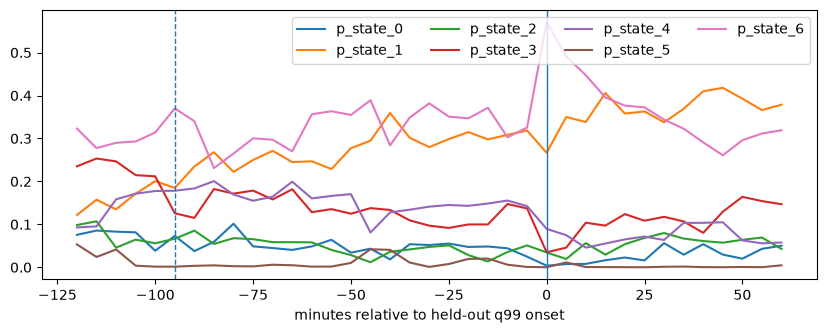

In [7]:
t0 = time.time()
dur_summary, dur_hazard = hb.duration_check(model, [Z[i] for i in te_idx], n_sims=N_SIMS)
print(f'duration simulation {time.time()-t0:.0f}s')
display(dur_summary.round(3))
align = hb.event_alignment(grid, ft_test, test_onsets, model.K)
if len(align):
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for c in state_cols:
        ax.plot(align.rel_min, align[c], label=c)
    ax.axvline(0, linewidth=1); ax.axvline(-95, linestyle='--', linewidth=1)
    ax.set_xlabel('minutes relative to held-out q99 onset'); ax.legend(ncol=4); plt.show()


In [8]:
params.to_csv(OUT / '06b_hour_normalizer.csv', index=False)
seq_meta.to_csv(OUT / '06b_sequence_metadata.csv', index=False)
comparison.to_csv(OUT / '06b_k_selection.csv', index=False)
pd.DataFrame(model.means, columns=E.columns).rename_axis('state').reset_index().to_csv(OUT / '06b_emission_means.csv', index=False)
pd.DataFrame(np.sqrt(model.variances), columns=E.columns).rename_axis('state').reset_index().to_csv(OUT / '06b_emission_sds.csv', index=False)
pd.DataFrame(model.A).rename_axis('from_state').reset_index().to_csv(OUT / '06b_transitions.csv', index=False)
ft_test.to_csv(OUT / '06b_filtered_test.csv', index=False)
pd.DataFrame([{'underlying': k, 'q99_threshold_train': v} for k, v in thr.items()]).to_csv(OUT / '06b_q99_train_thresholds.csv', index=False)
scores.to_csv(OUT / '06b_benchmark_scores.csv', index=False)
boot.to_csv(OUT / '06b_benchmark_bootstrap.csv', index=False)
hazard.to_csv(OUT / '06b_state_q99_hazard.csv', index=False)
dur_summary.to_csv(OUT / '06b_duration_summary.csv', index=False)
dur_hazard.to_csv(OUT / '06b_duration_hazard.csv', index=False)
align.to_csv(OUT / '06b_q99_alignment.csv', index=False)
(OUT / '06b_decision.json').write_text(json.dumps(decision, indent=2))
meta = {
    'version': hb.VERSION, 'module': '06b_hmm_vs_benchmark', 'emissions': list(E.columns),
    'normalization': 'training-only robust z per asset x UTC hour', 'missing_emissions': 'marginalized',
    'k_grid': list(K_VALUES), 'k_selected_by_validation_ll': int(k_sel), 'k_at_grid_edge': bool(k_sel == max(K_VALUES)),
    'train_fraction': TRAIN_FRACTION, 'test_start': str(pd.Timestamp(split.test_start_ns, tz='UTC')),
    'validation_start': str(pd.Timestamp(split.valid_start_ns, tz='UTC')),
    'n_unique_test_onset_timestamps': int(n_unique_test), 'decision': decision,
    'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()), 'n_rows': int(len(df)),
}
(OUT / '06b_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote', OUT)


wrote D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\06b
